# Imports

In [1]:
import os
# I need this to run torch on my computer, remove it according to your GPU ~Omar
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "11.0.0"

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt

/home/omarriad/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Verify Torch is working

# Data Preparation

## Loading the Dataset

In [3]:
notebook_folderPath = Path().absolute()
print(notebook_folderPath.parent)

/home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces


In [4]:
from datasets import Dataset, DatasetDict, load_from_disk
from dataset_preparer import load_and_split_dataset, LazyLoadingImageDataset

dataset_object_filepath = notebook_folderPath / "input"
dataset_source_folderpath = notebook_folderPath.parent.parent / "Datasets - Unsplit" / "X-Ray Region Classification"
labels = None #Loads all when set to None

dataset_augmentation_params = {
    "target_count_per_label": 3000,
    "rotation_range": 15,
    "flipping": True,
    "inverting": True,
    "shift_range": 0.1
}

if (dataset_object_filepath / "dataset_dict.json").is_file():
    print("Dataset Already Loaded, skipping split...")
    dataset = load_from_disk(str(dataset_object_filepath))
else:
    dataset = load_and_split_dataset(labels, dataset_source_folderpath, augmentation_params=dataset_augmentation_params)
    print("Dataset instance created...\nSaving Dataset Object for Future Use...")
    dataset.save_to_disk(str(dataset_object_filepath))

total_samples = sum(len(dataset[split]) for split in dataset.keys())
print("\nData Split by Percentage:")
for split in dataset.keys():
    num_samples = len(dataset[split])
    percentage = (num_samples / total_samples) * 100
    print(f"{split}: {num_samples} samples ({percentage:.2f}%)")

dataset

Dataset Already Loaded, skipping split...

Data Split by Percentage:
train: 18900 samples (70.00%)
validation: 5400 samples (20.00%)
test: 2700 samples (10.00%)


/home/omarriad/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['image_with_augmentation_params', 'label'],
        num_rows: 18900
    })
    validation: Dataset({
        features: ['image_with_augmentation_params', 'label'],
        num_rows: 5400
    })
    test: Dataset({
        features: ['image_with_augmentation_params', 'label'],
        num_rows: 2700
    })
})

In [5]:
unique_labels = set()

for row in dataset["train"]:
    unique_labels.add(row["label"])

unique_labels

{'Chest',
 'Elbow',
 'Finger',
 'Forearm',
 'Hand',
 'Humerus',
 'Shoulder',
 'Tibia_and_Fibula',
 'Wrist'}

In [6]:
dataset["train"] = LazyLoadingImageDataset(dataset["train"], size=(224, 224), padding=True)
dataset["validation"] = LazyLoadingImageDataset(dataset["validation"], size=(224, 224), padding=True)
dataset["test"] = LazyLoadingImageDataset(dataset["test"], size=(224, 224), padding=True)

## Sample Image

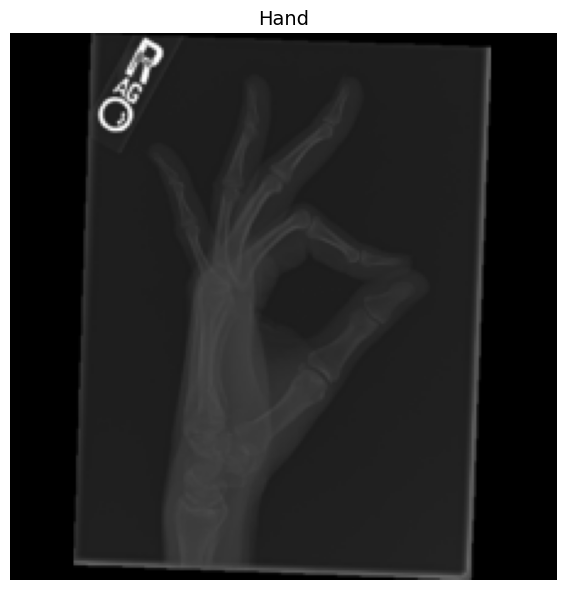

In [7]:
def plot_image_entry(entry):
    """
    Plot an image from a dataset entry with the label as title.
    
    Args:
        entry: Dictionary with 'image' and 'label' keys
    """
    image = entry["image"]
    label = entry["label"]
    
    plt.figure(figsize=(6, 6))
    plt.imshow(image, cmap='gray')
    plt.title(label, fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_image_entry(dataset["train"][18000])

# The model

## Loading the model

In [8]:
from transformers import AutoModelForImageClassification, AutoImageProcessor, MobileNetV2Config

image_processor = AutoImageProcessor.from_pretrained("google/mobilenet_v2_1.0_224") # Normalizes pixels and converts to tensors, image already resized by preparer

id2label = {i: label for i, label in enumerate(unique_labels)}
label2id = {label: i for i, label in enumerate(unique_labels)}
problem_type = "single_label_classification"

config = MobileNetV2Config.from_pretrained("google/mobilenet_v2_1.0_224", 
                                           id2label=id2label, 
                                           label2id=label2id, 
                                           num_labels=len(unique_labels), 
                                           problem_type=problem_type,
                                           )

model = AutoModelForImageClassification.from_pretrained("google/mobilenet_v2_1.0_224", config=config, ignore_mismatched_sizes=True) # The model itself
print(f"Label mapping: {id2label}")

You passed `num_labels=9` which is incompatible to the `id2label` map of length `1001`.
Loading weights: 100%|██████████| 314/314 [00:00<00:00, 14879.30it/s]
MobileNetV2ForImageClassification LOAD REPORT from: google/mobilenet_v2_1.0_224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1001]) vs model:torch.Size([9])            
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1001, 1280]) vs model:torch.Size([9, 1280])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Label mapping: {0: 'Hand', 1: 'Humerus', 2: 'Forearm', 3: 'Shoulder', 4: 'Elbow', 5: 'Tibia_and_Fibula', 6: 'Chest', 7: 'Finger', 8: 'Wrist'}


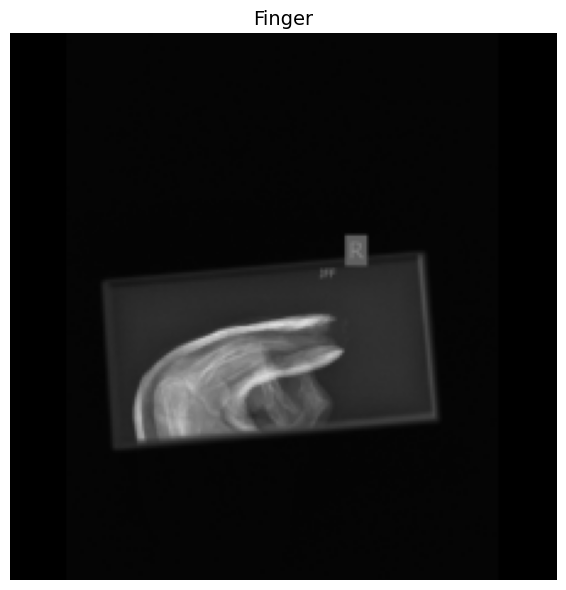

Predicted label: Tibia_and_Fibula (ID: 5)


/home/omarriad/.local/lib/python3.10/site-packages/torch/nn/modules/linear.py:125: UserWarning: Attempting to use hipBLASLt on an unsupported architecture! Overriding blas backend to hipblas (Triggered internally at ../aten/src/ATen/Context.cpp:296.)
  return F.linear(input, self.weight, self.bias)


In [ ]:
import torch
from torch import cuda

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

test_image_entry = dataset["train"][18000]

plot_image_entry(test_image_entry)

# Test with 1 image
model.eval()
with torch.no_grad():
    pixel_values = image_processor(test_image_entry["image"], return_tensors="pt")["pixel_values"].to(device)
    outputs = model(pixel_values)
    predicted_label_id = outputs.logits.argmax(-1).item()
    predicted_label = id2label[predicted_label_id]
    print(f"Predicted label: {predicted_label} (ID: {predicted_label_id})")



## Model Hyperparameters

In [10]:
# Device configuration
DATALOADER_NUM_WORKERS = 2 # If memory issue, decrease. If training is too slow, increase.
PIN_MEMORY = cuda.is_available()


# Model hyperparameters
EPOCHS = 50 # If overfitting, decrease. If underfitting, increase.
WARMUP_STEPS = 300 # If overfitting, increase. If underfitting, decrease.
GRADIENT_ACCUMULATION_STEPS = 1 # If memory issue, increase
BATCH_SIZE = 32 # If memory issue, decrease
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 1e-4 

## Training Setup

In [11]:
import numpy as np
from torch.utils.data import DataLoader

def collate_fn(batch):
    images = [item['image'] for item in batch]
    labels = torch.tensor([label2id[item['label']] for item in batch], dtype=torch.long)
    
    # Process only the batch images (not entire dataset)
    pixel_values = image_processor(images=images, return_tensors="pt")['pixel_values']
    
    return {
        'pixel_values': pixel_values,
        'labels': labels
    }

# Create PyTorch DataLoaders with lazy-loading (no upfront preprocessing!)
train_dataloader = DataLoader(
    dataset["train"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=DATALOADER_NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_dataloader = DataLoader(
    dataset["validation"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=DATALOADER_NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_dataloader = DataLoader(
    dataset["test"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=DATALOADER_NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

In [12]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
train_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_dataloader))

warmup_scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, 
                                                     start_factor=0.1, 
                                                     total_iters=WARMUP_STEPS
                                                     )

combined_scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, 
                                                           schedulers=[warmup_scheduler, train_scheduler], 
                                                           milestones=[WARMUP_STEPS])

## Training Loop

In [13]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from tqdm import tqdm
import json

checkpoint_dir = notebook_folderPath / "output" / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

final_model_dir = notebook_folderPath / "output" / "final_model"
final_model_dir.mkdir(parents=True, exist_ok=True)

logs_path = checkpoint_dir / f"training_logs.json"
if logs_path.is_file():
    with open(logs_path, 'r') as f:
        training_logs = json.load(f)
else:
    training_logs = []

total_steps = EPOCHS * len(train_dataloader)
checkpoint_interval = 5

patience_counter = 0
early_stopping_patience = 5

# Resume from latest checkpoint if it exists
checkpoints = sorted(checkpoint_dir.glob("checkpoint_epoch_*.pt"))
if checkpoints:
    latest_checkpoint = checkpoints[-1]
    print(f"Loading checkpoint: {latest_checkpoint}")
    checkpoint = torch.load(latest_checkpoint, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    combined_scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    global_step = checkpoint['epoch'] * len(train_dataloader)
    start_epoch = checkpoint['epoch'] + 1
    print(f"Resumed from epoch {checkpoint['epoch']}, global_step={global_step}")
else:
    start_epoch = 1

best_val_loss = float('inf')
best_model_epoch = 0

best_checkpoint_path = checkpoint_dir / f"best_model_yet.pt"

for epoch in tqdm(range(start_epoch, EPOCHS + 1), desc="Training Progress"):
    model.train()
    correct = 0
    total = 0
    train_loss = 0.0
    # Training loop & gradient accumulation
    step = 0
    patience_counter += 1
    for batch in train_dataloader:
        pixel_values = batch['pixel_values'].to(device)
        labels = batch['labels'].to(device)
        
        outputs = model(pixel_values=pixel_values, labels=labels)
        loss = outputs.loss
        logits = outputs.logits
        
        loss.backward()
        train_loss += loss.item()
        
        if (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0:
            optimizer.step()
            optimizer.zero_grad()

        combined_scheduler.step()
        
        
        _, predicted = torch.max(logits, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

        step += 1
        
    train_accuracy = correct / total
    avg_train_loss = train_loss / len(train_dataloader)
    
    # store checkpoints
    if epoch % checkpoint_interval == 0:
        checkpoint_path = checkpoint_dir / f"checkpoint_epoch_{epoch}.pt"
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': combined_scheduler.state_dict(),
        }, checkpoint_path)
    
    # Validation loop
    model.eval()
    correct = 0
    total = 0
    val_loss = 0.0
    with torch.no_grad():
        for batch in val_dataloader:
            pixel_values = batch['pixel_values'].to(device)
            labels = batch['labels'].to(device)
            
            outputs = model(pixel_values=pixel_values, labels=labels)
            logits = outputs.logits
            loss = outputs.loss
            
            val_loss += loss.item()
            _, predicted = torch.max(logits, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    val_accuracy = correct / total
    avg_val_loss = val_loss / len(val_dataloader)

    # update best model if validation loss improved
    if avg_val_loss < best_val_loss:
        patience_counter = 0
        best_val_loss = avg_val_loss
        best_model_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': combined_scheduler.state_dict(),
        }, best_checkpoint_path)
    
    # Log metrics
    training_logs.append({
        'epoch': epoch,
        'train_loss': avg_train_loss,
        'train_accuracy': train_accuracy,
        'val_loss': avg_val_loss,
        'val_accuracy': val_accuracy
    })

    # save training logs after each epoch
    with open(logs_path, 'w') as f:
        json.dump(training_logs, f, indent=2)

    if patience_counter >= early_stopping_patience:
        print(f"Early stopping triggered at epoch {epoch} due to no improvement in validation loss for {early_stopping_patience} consecutive epochs.")
        break


# load best model for testing
best_checkpoint = torch.load(best_checkpoint_path, map_location=device)
model.load_state_dict(best_checkpoint['model_state_dict'])

# Save final model
print("\nTraining complete! Saving final model...")
model.save_pretrained(str(final_model_dir))
image_processor.save_pretrained(str(final_model_dir))

with open(logs_path, 'w') as f:
    json.dump(training_logs, f, indent=2)
print(f"Model saved to {final_model_dir}")
print(f"Training logs saved to {logs_path}")

Training Progress:  26%|██▌       | 13/50 [27:06<1:17:10, 125.15s/it]
/tmp/ipykernel_140209/826753806.py:142: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_checkpoint =

Early stopping triggered at epoch 14 due to no improvement in validation loss for 5 consecutive epochs.

Training complete! Saving final model...


Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 54.96it/s]

Model saved to /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Region Classification/output/final_model
Training logs saved to /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces/X-Ray Region Classification/output/checkpoints/training_logs.json


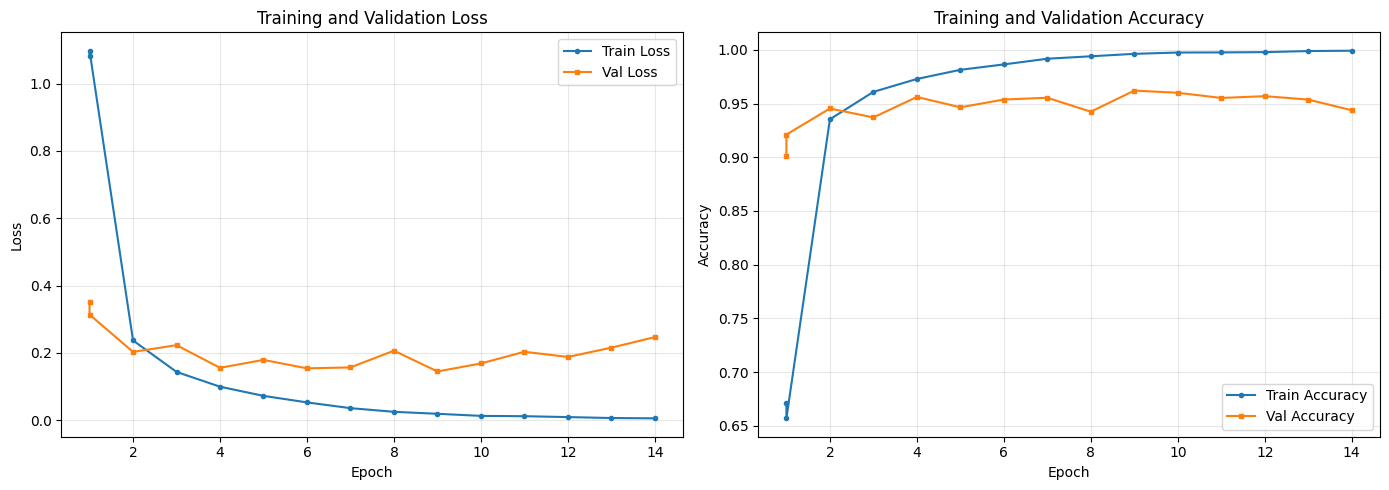

Best Val Accuracy: 0.9620 at Epoch 9
Best Val Loss: 0.1446 at Epoch 9


In [14]:
# Plot training metrics
import matplotlib.pyplot as plt

epochs = [log['epoch'] for log in training_logs]
train_losses = [log['train_loss'] for log in training_logs]
val_losses = [log['val_loss'] for log in training_logs]
train_accs = [log['train_accuracy'] for log in training_logs]
val_accs = [log['val_accuracy'] for log in training_logs]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot loss
axes[0].plot(epochs, train_losses, label='Train Loss', marker='o', markersize=3)
axes[0].plot(epochs, val_losses, label='Val Loss', marker='s', markersize=3)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot accuracy
axes[1].plot(epochs, train_accs, label='Train Accuracy', marker='o', markersize=3)
axes[1].plot(epochs, val_accs, label='Val Accuracy', marker='s', markersize=3)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Best Val Accuracy: {max(val_accs):.4f} at Epoch {epochs[val_accs.index(max(val_accs))]}")
print(f"Best Val Loss: {min(val_losses):.4f} at Epoch {epochs[val_losses.index(min(val_losses))]}")

## Run on Test set